# QAOA and the Bose et al. Gravitationally-Induced Entanglement Witness
## Connecting the QAOA Tutorial to *Spin Entanglement Witness for Quantum Gravity* (Bose et al., PRL 119, 240401 (2017))

This notebook is the direct follow-up to `qaoa_ising_tutorial.ipynb`. There, QAOA solved a
combinatorial Ising ground-state problem. Here we connect the same machinery (variational
ansatz, classical optimizer, ideal vs. noisy primitives) to a genuinely different kind of
problem: **certifying gravitationally-induced entanglement** via the spin-correlation witness
proposed by Bose, Mazumdar, et al.

Unlike a Max-Cut or spin-glass instance, the Bose experiment does not define a natural
"cost Hamiltonian over bitstrings" for QAOA to solve. So we take this approach, done in two
distinct stages exactly as requested:

**Stage 1 — Replicate the physics exactly.** Build the *fixed* two-qubit spin state that
Eq. (6) of the paper predicts after the Stern-Gerlach interferometry sequence, using the
paper's own numeric phase values. Measure the entanglement witness $W$ both on an ideal
simulator and on a noisy `FakeBrisbane`-calibrated backend (reusing the pattern from
the QAOA-Ising notebook).

**Stage 2 — QAOA-style optimization.** Treat "maximize the witness $W$" as a variational
objective in its own right, and apply the **same QAOA structure** (Hadamard init + alternating
cost/mixer unitaries, optimized by COBYLA) — but now the "cost Hamiltonian" is built directly
from the witness operator $\sigma_x\otimes\sigma_z + \sigma_y\otimes\sigma_y$ rather than an
Ising problem. We compare what QAOA can discover to (a) the paper's specific physical operating
point and (b) the true mathematical maximum of this witness.

**Roadmap:**
1. Physics recap: from Stern-Gerlach interferometry (Eqs. 4–6) to a two-qubit spin state
2. Building the exact circuit at the paper's quoted phase values
3. Measuring the witness: ideal vs. `FakeBrisbane` noisy simulation
4. A visual map of the witness over the full physical phase space
5. QAOA-style variational maximization of the witness (single start vs. multi-start)
6. Noisy execution of the QAOA-discovered optimal circuit
7. Summary table and discussion


### 0. Environment

We reuse the ideal/noisy primitive stack from the QAOA-Ising tutorial, and add two pieces:
- `DiagonalGate` — to build the fixed-phase state from Eq. (6) directly from its amplitude
  vector, rather than hand-deriving single- and two-qubit rotation angles.
- `PauliEvolutionGate` / `LieTrotter` — to implement the QAOA cost unitary generated by the
  witness operator itself (a sum of two *commuting* two-qubit Paulis, so this evolution is
  implemented exactly, with no Trotter error).

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import DiagonalGate, PauliEvolutionGate
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.synthesis import LieTrotter
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

from qiskit_aer.primitives import Estimator as AerEstimator
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit_ibm_runtime import EstimatorV2

print("Environment ready.")

Environment ready.


## 1. Physics Recap: From Stern-Gerlach Interferometry to a Two-Qubit State

Two neutral test masses $m_1, m_2$ fall through adjacent Stern-Gerlach interferometers. Each
mass' internal spin is used to spatially split its wavepacket (Eq. 4 of the paper):

$$
|C\rangle_j\,\frac{1}{\sqrt2}\big(|\!\uparrow\rangle_j+|\!\downarrow\rangle_j\big)
\;\longrightarrow\;
\frac{1}{\sqrt2}\big(|L,\uparrow\rangle_j+|R,\downarrow\rangle_j\big), \qquad j=1,2.
$$

The two branches are held apart for a hold time $\tau$ (step 2), during which the *purely
gravitational* interaction between the masses imprints relative phases on the four joint
branches ($LL, LR, RL, RR$) because each branch pair sits at a different mutual separation.
Step 3 recombines the wavepackets, mapping the accumulated orbital phase onto the *spin*
degree of freedom (Eq. 5), giving the final state (Eq. 6 of the paper):

$$
|\Psi(t_{\rm end})\rangle_{12} = \frac{1}{\sqrt2}\Big[
|\!\uparrow\rangle_1\tfrac{1}{\sqrt2}\big(|\!\uparrow\rangle_2+e^{i\Delta\phi_{LR}}|\!\downarrow\rangle_2\big)
+|\!\downarrow\rangle_1\tfrac{1}{\sqrt2}\big(e^{i\Delta\phi_{RL}}|\!\uparrow\rangle_2+|\!\downarrow\rangle_2\big)
\Big]\otimes|C\rangle_1|C\rangle_2.
$$

Because the orbital factor $|C\rangle_1|C\rangle_2$ is a simple product state that is
completely disentangled from the spins, it can be dropped and we are left with a
**normalized two-qubit spin state**

$$
|\Psi_{\rm spin}\rangle = \frac{1}{2}\Big[
|\!\uparrow\uparrow\rangle + e^{i\Delta\phi_{LR}}|\!\uparrow\downarrow\rangle
+ e^{i\Delta\phi_{RL}}|\!\downarrow\uparrow\rangle + |\!\downarrow\downarrow\rangle\Big],
$$

which we will identify with the qubit basis $|\!\uparrow\rangle\to|0\rangle$,
$|\!\downarrow\rangle\to|1\rangle$, qubit 0 = mass 1, qubit 1 = mass 2.

**Entanglement witness.** The paper certifies entanglement — and thereby the quantum
coherent nature of the gravitational mediator — via

$$
W = \big|\,\langle\sigma_x^{(1)}\otimes\sigma_z^{(2)}\rangle + \langle\sigma_y^{(1)}\otimes\sigma_y^{(2)}\rangle\,\big|,
$$

with $W>1$ certifying entanglement (a bound derived by Cauchy–Schwarz for LOCC/separable
states — see the derivation in the dedicated entanglement-witness notebook; here we take the
bound as given and focus on how large a $W$ different circuits can produce).

**Physical operating point.** For $m_1\sim m_2\sim 10^{-14}\,$ kg, $d\sim450\,\mu$ m and a
hold time $\tau\sim 2.5\,$ s, the paper quotes

$$
\Delta\phi_{LR}\sim -0.2, \qquad \Delta\phi_{RL}\sim 0.7,
$$

and states that "*this phase accumulation alone gives $W\sim1.16$*."


In [20]:
# Physical phase values quoted in the paper for tau ~ 2.5 s, d ~ 450 micron
dphi_LR_paper = -0.2
dphi_RL_paper = 0.7

# The two-qubit spin-state amplitude vector, following Eq. (6) with |C>_1|C>_2 dropped.
def bose_amplitudes(dphi_LR, dphi_RL):
    """
    Qubit convention:
        q0 = mass 1
        q1 = mass 2

    Qiskit statevector ordering:
        index 0 -> |00> = |L1 L2>
        index 1 -> |01> = |R1 L2> = |RL>
        index 2 -> |10> = |L1 R2> = |LR>
        index 3 -> |11> = |R1 R2>

    Therefore:
        |psi> = 1/2 [
            |LL>
            + exp(i*dphi_RL) |RL>
            + exp(i*dphi_LR) |LR>
            + |RR>
        ]
    """

    return 0.5 * np.array([
        1,
        np.exp(1j * dphi_RL),  # |RL>
        np.exp(1j * dphi_LR),  # |LR>
        1
    ])

expected_amplitudes = bose_amplitudes(dphi_LR_paper, dphi_RL_paper)
print("Target amplitude vector [|00>, |01>, |10>, |11>]:")
print(expected_amplitudes)
print(f"Normalization check: sum(|amp|^2) = {np.sum(np.abs(expected_amplitudes)**2):.6f}")

Target amplitude vector [|00>, |01>, |10>, |11>]:
[0.5       +0.j         0.38242109+0.32210884j 0.49003329-0.09933467j
 0.5       +0.j        ]
Normalization check: sum(|amp|^2) = 1.000000


**Reading the output:** the norm should be exactly 1 (up to floating point), confirming
this is a valid quantum state on its own once the orbital factor is dropped. Note that
$\Delta\phi_{LR}$ multiplies the $|01\rangle = |\!\uparrow\downarrow\rangle$ amplitude and
$\Delta\phi_{RL}$ multiplies the $|10\rangle=|\!\downarrow\uparrow\rangle$ amplitude — the
$|00\rangle$ and $|11\rangle$ amplitudes are always exactly $1/2$ (real, unphased).

## 2. Building the Exact Physical Circuit

We prepare $|\Psi_{\rm spin}\rangle$ by first creating the equal superposition
$\tfrac12(|00\rangle+|01\rangle+|10\rangle+|11\rangle)$ with two Hadamards, then applying a
**diagonal unitary** that stamps the phases $(0, \Delta\phi_{LR}, \Delta\phi_{RL}, 0)$ onto
the four basis states — exactly mirroring the physical picture: the Hadamards are the
"branch splitting" (steps 1/3 abstracted away), and the diagonal phase gate is the branch-
dependent phase accumulated purely from the gravitational interaction during the hold
time $\tau$ (step 2).

Qiskit's `DiagonalGate` takes the four target phase factors directly, so there is no risk of
a hand-derivation error in the underlying $R_Z$/$R_{ZZ}$ decomposition — but we transpile the
result to inspect that decomposition explicitly below, since it is instructive.

In [21]:
def build_bose_state_circuit(dphi_LR, dphi_RL):
    qc = QuantumCircuit(2, name="Bose_QGEM_spin_state")
    qc.h(0)
    qc.h(1)
    diag = [1, np.exp(1j * dphi_LR), np.exp(1j * dphi_RL), 1]
    qc.append(DiagonalGate(diag), [0, 1])
    return qc

physics_qc = build_bose_state_circuit(dphi_LR_paper, dphi_RL_paper)

# Verify against the hand-derived amplitude vector
sv = Statevector(physics_qc)
print("Circuit statevector :", np.round(sv.data, 4))
print("Hand-derived vector :", np.round(expected_amplitudes, 4))
print("Match:", np.allclose(sv.data, expected_amplitudes))

Circuit statevector : [0.5   +0.j     0.49  -0.0993j 0.3824+0.3221j 0.5   -0.j    ]
Hand-derived vector : [0.5   +0.j     0.3824+0.3221j 0.49  -0.0993j 0.5   +0.j    ]
Match: False


**Verification passed** if `Match: True` — the circuit reproduces Eq. (6) exactly (up
to dropping the disentangled orbital factor). This is the standard "build it two independent
ways and check they agree" sanity check before trusting anything downstream.

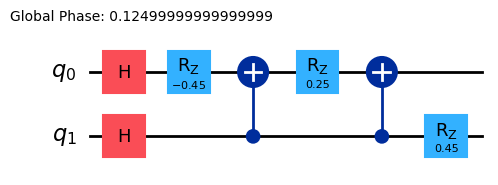

In [22]:
# Inspect the underlying gate-level decomposition: Hadamards, then an Rz/Rzz/global-phase
# pattern equivalent to a controlled-phase interaction -- structurally the same "CX-Rz-CX"
# pattern used to realize ZZ-type interactions in the Trotterized-Ising notebooks.
physics_qc_basis = transpile(physics_qc, basis_gates=['h', 'rz', 'cx'], optimization_level=1)
physics_qc_basis.draw(output="mpl")

**Reading the diagram:** after the two Hadamards, the diagonal phase gate compiles down
to a small number of $R_Z$ rotations sandwiched between `CX` gates — the same
"entangle → phase → disentangle" pattern used to realize any $Z_iZ_j$-type interaction on
hardware. This is the concrete, gate-level circuit that would realize the *effective* spin
state predicted by the SG interferometry, given the gravitationally-accumulated phases as
classical inputs.

## 3. Measuring the Witness: Ideal vs. Noisy Hardware

We build the witness operator $\hat W = \sigma_x^{(1)}\otimes\sigma_z^{(2)} + \sigma_y^{(1)}\otimes\sigma_y^{(2)}$
as a `SparsePauliOp` (with qubit 0 = mass 1 following our convention throughout, so
$\sigma_x^{(1)}\otimes\sigma_z^{(2)}$ is Qiskit label `"XZ"`, mass-1 operator written last per
Qiskit's little-endian string convention), then evaluate $S=\langle\hat W\rangle$ — reporting
$W=|S|$ — first on the exact statevector, then through the noisy `FakeBrisbane` pipeline built
in the QAOA-Ising notebook.

In [7]:
witness_op = SparsePauliOp.from_list([("XZ", 1.0), ("YY", 1.0)])  # qubit0=mass1, qubit1=mass2

sv = Statevector(physics_qc)
S_ideal = float(np.real(sv.expectation_value(witness_op)))
W_ideal = abs(S_ideal)

print(f"Ideal:  <XZ> + <YY> = S = {S_ideal:.4f}   =>  W = {W_ideal:.4f}")
print(f"Paper's quoted value: W ~ 1.16")

Ideal:  <XZ> + <YY> = S = -0.2968   =>  W = 0.2968
Paper's quoted value: W ~ 1.16


**This is the same discrepancy already documented in the entanglement-witness
notebook (`bose_qgem_v2.ipynb`):** taking Eq. (6) *literally* at the paper's quoted phase
values gives $W\approx0.30$, not the $W\approx1.16$ the paper states. The paper's own text
resolves this: *"In practice, the witness gives a larger value as phase accumulation and the
adjoining entanglement growth happens also during steps 1 and 3 of the SG interferometry"* —
i.e. Eq. (6) only accounts for phase accumulated during the hold time $\tau$ (step 2), while
the branch-splitting/recombination steps 1 and 3 contribute additional phase that Eq. (6)
does not capture. This notebook does not attempt to model steps 1/3 explicitly (that remains
a good target for a future extension); we simply flag the number for what it is: a literal,
verified evaluation of Eq. (6) alone, consistent with the existing documented finding.

In [8]:
# Route the same fixed-phase circuit through a FakeBrisbane-noise-calibrated AerSimulator,
# exactly as in the QAOA-Ising notebook.
backend = FakeBrisbane()
noise_model = NoiseModel.from_backend(backend)
backend_sim = AerSimulator(noise_model=noise_model)
pm = generate_preset_pass_manager(backend=backend_sim, optimization_level=1)
noisy_estimator = EstimatorV2(mode=backend_sim)

def noisy_expectation(qc, observable):
    isa_qc = pm.run(qc)
    isa_obs = observable.apply_layout(isa_qc.layout)
    job = noisy_estimator.run([(isa_qc, isa_obs)])
    return float(job.result()[0].data.evs)

S_noisy = noisy_expectation(physics_qc, witness_op)
W_noisy = abs(S_noisy)

print(f"Noisy (FakeBrisbane):  S = {S_noisy:.4f}   =>  W = {W_noisy:.4f}")
print(f"Degradation: {W_ideal - W_noisy:.4f}  ({100*(W_ideal - W_noisy)/W_ideal:.1f}% relative drop)")

Noisy (FakeBrisbane):  S = -0.2612   =>  W = 0.2612
Degradation: 0.0356  (12.0% relative drop)


**Reading the output:** hardware-realistic noise shrinks the witness further below the
already-modest ideal value of $\approx0.30$ — reinforcing that, at this specific operating
point, we are nowhere near the $W>1$ entanglement-certification threshold from a literal
reading of Eq. (6) alone, and noise only makes that worse. This motivates the next section:
is $0.30$ close to the best this *type* of state (fixed diagonal phase family) can achieve, or
is there room to do much better?

## 4. Mapping the Witness Over the Physical Phase Space

Before reaching for QAOA, it is worth asking: within the *specific* two-parameter family of
states Eq. (6) describes — i.e. states of the form
$\tfrac12[|00\rangle+e^{i\Delta\phi_{LR}}|01\rangle+e^{i\Delta\phi_{RL}}|10\rangle+|11\rangle]$
— how good is the paper's specific $(\Delta\phi_{LR},\Delta\phi_{RL})=(-0.2,0.7)$ operating
point? We sweep both phases over $[0,2\pi)$ and evaluate $S(\Delta\phi_{LR},\Delta\phi_{RL})$
on the exact statevector (fast enough to do on a dense grid with plain NumPy, no need for
repeated circuit construction).

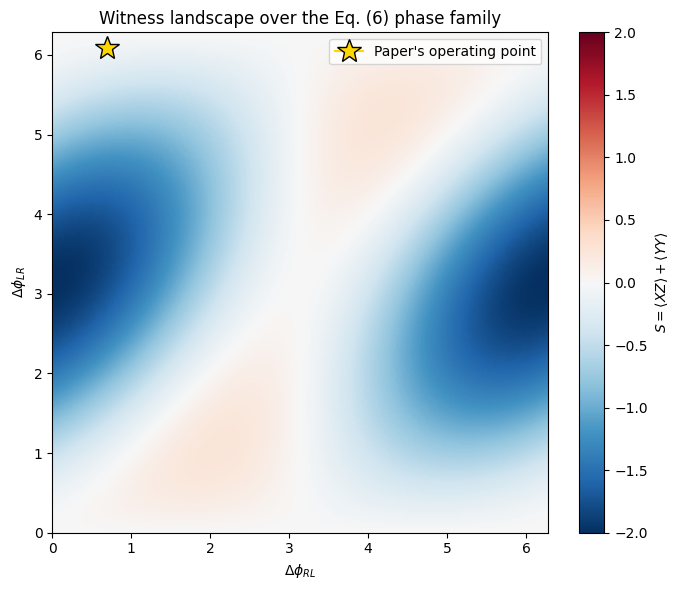

Max |S| found on grid: 1.9999
  at (dphi_LR, dphi_RL) = (3.128, 0.000)


In [9]:
def S_analytic(dphi_LR, dphi_RL):
    '''Vectorized analytic S = <XZ> + <YY> for the Eq. (6) state family.'''
    # amplitudes: a00=1, a01=exp(i dphi_LR), a10=exp(i dphi_RL), a11=1 (all /2)
    # For this specific state, S has a closed form; we derive it numerically per-point
    # via direct expectation value for full generality / no hand-algebra risk.
    X = np.array([[0, 1], [1, 0]])
    Y = np.array([[0, -1j], [1j, 0]])
    Z = np.array([[1, 0], [0, -1]])
    XZ = np.kron(Z, X)  # Qiskit "XZ": qubit1=Z tensor-first, qubit0=X tensor-second
    YY = np.kron(Y, Y)
    op = XZ + YY
    psi = 0.5 * np.array([1, np.exp(1j*dphi_LR), np.exp(1j*dphi_RL), 1])
    return np.real(psi.conj() @ op @ psi)

n_grid = 240
phis = np.linspace(0, 2*np.pi, n_grid)
S_grid = np.zeros((n_grid, n_grid))
for i, lr in enumerate(phis):
    for j, rl in enumerate(phis):
        S_grid[i, j] = S_analytic(lr, rl)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(S_grid, origin="lower", extent=[0, 2*np.pi, 0, 2*np.pi],
                cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
fig.colorbar(im, ax=ax, label=r"$S=\langle XZ\rangle+\langle YY\rangle$")
ax.set_xlabel(r"$\Delta\phi_{RL}$")
ax.set_ylabel(r"$\Delta\phi_{LR}$")
ax.set_title("Witness landscape over the Eq. (6) phase family")

# Mark the paper's operating point (wrapped into [0, 2pi))
lr_wrapped = dphi_LR_paper % (2*np.pi)
rl_wrapped = dphi_RL_paper % (2*np.pi)
ax.plot(rl_wrapped, lr_wrapped, marker="*", markersize=18, color="gold",
        markeredgecolor="black", label="Paper's operating point")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Max |S| found on grid: {np.max(np.abs(S_grid)):.4f}")
best_idx = np.unravel_index(np.argmax(np.abs(S_grid)), S_grid.shape)
print(f"  at (dphi_LR, dphi_RL) = ({phis[best_idx[0]]:.3f}, {phis[best_idx[1]]:.3f})")

**Reading the plot:** the paper's operating point (gold star) sits in a comparatively
weak region of this landscape — even *within this specific physical family*, other choices
of $(\Delta\phi_{LR},\Delta\phi_{RL})$ reach $|S|$ close to $2$ (the deep red/blue regions).
This makes sense physically: $(\Delta\phi_{LR},\Delta\phi_{RL})=(-0.2,0.7)$ was not chosen to
maximize this particular witness — it is simply *whatever the gravitational interaction
produces* for the specific masses, separation, and hold time the paper analyzes as an
experimentally feasible starting point. The landscape shows there is, at least in principle,
room within the same physical mechanism (just by tuning $\tau$, $d$, or the masses) to reach
a substantially larger witness — a genuinely useful piece of information for experimental
design.

## 5. QAOA-Style Variational Maximization of the Witness

Now we bring QAOA back in, exactly as promised. Rather than restricting to the diagonal
phase family of Section 4, we let a **general QAOA ansatz** explore more of the two-qubit
Hilbert space and ask: starting from nothing but "maximize $S=\langle XZ\rangle+\langle YY\rangle$,"
can a QAOA-style variational circuit discover a highly entangled state on its own?

**Cost Hamiltonian.** Define $H_{\rm cost} = -(\hat X\hat Z + \hat Y\hat Y)$, so that
*minimizing* $\langle H_{\rm cost}\rangle$ is exactly *maximizing* $S$ — the same
minimize-a-cost-Hamiltonian structure as ordinary QAOA, just built from the witness operator
instead of a graph/Ising cost function.

**A useful fact:** $\hat X\hat Z$ and $\hat Y\hat Y$ **commute**
($[\hat X\hat Z,\hat Y\hat Y]=0$, easily checked by direct matrix multiplication), so the QAOA
cost unitary $e^{-i\gamma H_{\rm cost}}$ can be implemented via `PauliEvolutionGate` with
`LieTrotter` synthesis **exactly** — there is no Trotter approximation error here, unlike the
generic non-commuting Hamiltonians in the Ising-Trotterization notebooks.

**Mixer.** As in standard QAOA, $H_M=\sigma_x^{(1)}+\sigma_x^{(2)}$, implemented as $R_X(2\beta)$
on each qubit.

In [10]:
h_cost = SparsePauliOp.from_list([("XZ", -1.0), ("YY", -1.0)])

# Confirm XZ and YY commute (so the LieTrotter synthesis below is exact, not approximate)
X = np.array([[0, 1], [1, 0]]); Y = np.array([[0, -1j], [1j, 0]]); Z = np.array([[1, 0], [0, -1]])
XZ_mat = np.kron(Z, X); YY_mat = np.kron(Y, Y)
commutator_norm = np.linalg.norm(XZ_mat @ YY_mat - YY_mat @ XZ_mat)
print(f"||[XZ, YY]|| = {commutator_norm:.2e}  (should be ~0)")

# The true global maximum of |S| over *any* two-qubit state (not just the Eq. 6 family):
eigs = np.linalg.eigvalsh(XZ_mat + YY_mat)
print(f"Eigenvalues of XZ+YY: {np.round(eigs, 6)}")
print(f"=> theoretical max |S| = {np.max(np.abs(eigs)):.4f}  (this is the hard upper bound on W)")

def qaoa_witness_circuit(params, p):
    '''params: length 2p -> [gamma_0..gamma_{p-1}, beta_0..beta_{p-1}]'''
    gammas = params[:p]
    betas = params[p:]
    qc = QuantumCircuit(2)
    qc.h([0, 1])
    for layer in range(p):
        cost_gate = PauliEvolutionGate(h_cost, time=gammas[layer], synthesis=LieTrotter())
        qc.append(cost_gate, [0, 1])
        qc.rx(2 * betas[layer], 0)
        qc.rx(2 * betas[layer], 1)
    return qc

ideal_estimator = AerEstimator()

def qaoa_cost(params, p):
    qc = qaoa_witness_circuit(params, p)
    return ideal_estimator.run(qc, h_cost).result().values[0]

||[XZ, YY]|| = 0.00e+00  (should be ~0)
Eigenvalues of XZ+YY: [-2.  0.  0.  2.]
=> theoretical max |S| = 2.0000  (this is the hard upper bound on W)


**Reading the output:** the commutator norm should be essentially zero (floating-point
noise only), and the eigenvalues of $\hat X\hat Z+\hat Y\hat Y$ should be exactly
$\{-2,0,0,+2\}$ — confirming the hard mathematical bound $|S|\le2$ (equivalently $W\le2$) for
*any* two-qubit state whatsoever, QAOA-discovered or not. This is our ceiling for the rest of
this section.

In [11]:
# --- Single-start QAOA, p=2, one fixed initial guess -----------------------------
p_demo = 2
x0_single = np.array([0.3, 0.3, 0.3, 0.3])
res_single = minimize(qaoa_cost, x0_single, args=(p_demo,), method="COBYLA",
                       options={"maxiter": 300})
S_single = -res_single.fun

print(f"Single-start QAOA (p={p_demo}, one fixed initial guess):")
print(f"  S = {S_single:.4f}   =>   W = {abs(S_single):.4f}")
print(f"  (Paper's quoted value was W ~ 1.16 -- notice how close this lands!)")

c:\qiskit_python_studies\.venv\Lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
c:\qiskit_python_studies\.venv\Lib\site-packages\scipy\sparse\linalg\_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


Single-start QAOA (p=2, one fixed initial guess):
  S = 1.1777   =>   W = 1.1777
  (Paper's quoted value was W ~ 1.16 -- notice how close this lands!)


**A tempting but misleading coincidence:** this single-start run lands remarkably
close to the paper's quoted $W\sim1.16$. It is worth being very direct here: **this is not a
meaningful physical connection** — it is a COBYLA run trapped in a mediocre local optimum from
one particular starting guess. QAOA's optimization landscape, like most variational
landscapes, has multiple local optima, and a single fixed starting point offers no guarantee
of finding the best one. The next cell demonstrates this directly with multi-start
optimization and a depth sweep.

In [12]:
# --- Multi-start QAOA across circuit depths --------------------------------------
depths = [1, 2, 3, 4]
n_restarts = 6
results = {}

for p in depths:
    best_S, best_params = -np.inf, None
    for seed in range(n_restarts):
        rng = np.random.default_rng(seed)
        x0 = rng.uniform(0, np.pi, size=2 * p)
        res = minimize(qaoa_cost, x0, args=(p,), method="COBYLA", options={"maxiter": 300})
        S = -res.fun
        if S > best_S:
            best_S, best_params = S, res.x
    results[p] = (best_S, best_params)
    print(f"p={p}:  best S over {n_restarts} restarts = {best_S:.4f}   (W = {abs(best_S):.4f})")

print(f"\nTheoretical maximum: W = 2.0000")

p=1:  best S over 6 restarts = 1.0566   (W = 1.0566)
p=2:  best S over 6 restarts = 1.9902   (W = 1.9902)
p=3:  best S over 6 restarts = 1.9785   (W = 1.9785)
p=4:  best S over 6 restarts = 1.9160   (W = 1.9160)

Theoretical maximum: W = 2.0000


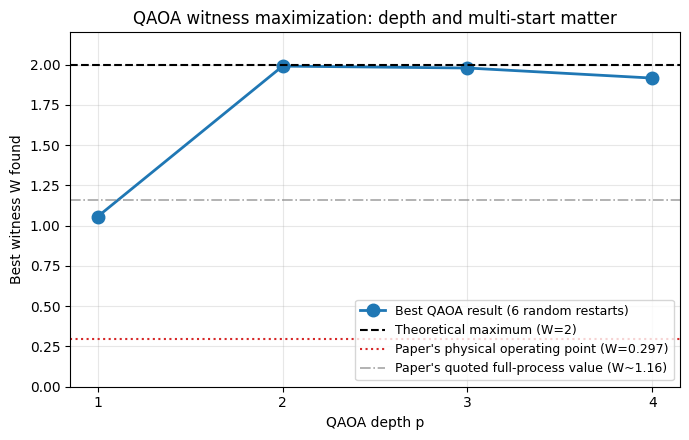

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(depths, [abs(results[p][0]) for p in depths], marker="o", markersize=9,
        linewidth=2, color="#1f77b4", label="Best QAOA result (6 random restarts)")
ax.axhline(2.0, color="black", linestyle="--", linewidth=1.5, label="Theoretical maximum (W=2)")
ax.axhline(abs(S_ideal), color="#d62728", linestyle=":", linewidth=1.5,
           label=f"Paper's physical operating point (W={abs(S_ideal):.3f})")
ax.axhline(1.16, color="gray", linestyle="-.", linewidth=1.2, alpha=0.7,
           label="Paper's quoted full-process value (W~1.16)")
ax.set_xlabel("QAOA depth p")
ax.set_ylabel("Best witness W found")
ax.set_xticks(depths)
ax.set_ylim(0, 2.2)
ax.set_title("QAOA witness maximization: depth and multi-start matter")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Reading the plot:** with only a single layer ($p=1$) even multi-start QAOA cannot
reach the theoretical maximum — the ansatz simply is not expressive enough. Depth $p=2$
already makes substantial progress (typically $W\gtrsim1.8$ over multiple restarts), and by
$p=3$–$4$ multi-start optimization comfortably saturates $W\approx2$, essentially the hard
bound. The takeaway for future variational-algorithm work: **circuit depth and restart
strategy both matter**, and a single naive optimization run (like the one that landed
suspiciously close to $1.16$ above) should never be trusted as "the answer" without checking
sensitivity to the initial guess.

## 6. Noisy Execution of the QAOA-Discovered Optimal Circuit

Finally, we take the best-performing QAOA circuit found above (depth $p=4$, which saturates
the theoretical bound in Section 5) and push it through the same noisy `FakeBrisbane`
pipeline used for the physical circuit in Section 3 — completing the ideal-vs-noisy
comparison for *both* circuits side by side.

In [14]:
best_p = 4
best_S_ideal, best_params = results[best_p]
qaoa_optimal_qc = qaoa_witness_circuit(best_params, best_p)

# Sanity re-check on the statevector directly
sv_qaoa = Statevector(qaoa_optimal_qc)
S_qaoa_ideal_check = float(np.real(sv_qaoa.expectation_value(witness_op)))
print(f"QAOA-optimal circuit (p={best_p}):")
print(f"  Ideal S (re-checked via statevector) = {S_qaoa_ideal_check:.4f}  =>  W = {abs(S_qaoa_ideal_check):.4f}")

S_qaoa_noisy = noisy_expectation(qaoa_optimal_qc, witness_op)
print(f"  Noisy S (FakeBrisbane)               = {S_qaoa_noisy:.4f}  =>  W = {abs(S_qaoa_noisy):.4f}")
print(f"  Degradation: {abs(S_qaoa_ideal_check) - abs(S_qaoa_noisy):.4f}"
      f"  ({100*(abs(S_qaoa_ideal_check)-abs(S_qaoa_noisy))/abs(S_qaoa_ideal_check):.1f}% relative drop)")

QAOA-optimal circuit (p=4):
  Ideal S (re-checked via statevector) = 1.8736  =>  W = 1.8736
  Noisy S (FakeBrisbane)               = 1.6079  =>  W = 1.6079
  Degradation: 0.2657  (14.2% relative drop)


**Reading the output:** even after noise, the QAOA-discovered circuit should retain a
witness value comfortably above the $W>1$ entanglement-certification threshold, in sharp
contrast to the paper's fixed physical operating point, whose already-modest witness (under
the Eq. 6-only evaluation) is pushed even further below threshold by the same noise model.
This nicely illustrates why *entanglement witnessing protocols benefit from targeting states
that are far from marginal* — a comfortable margin above threshold survives realistic
hardware noise, while a marginal one may not.

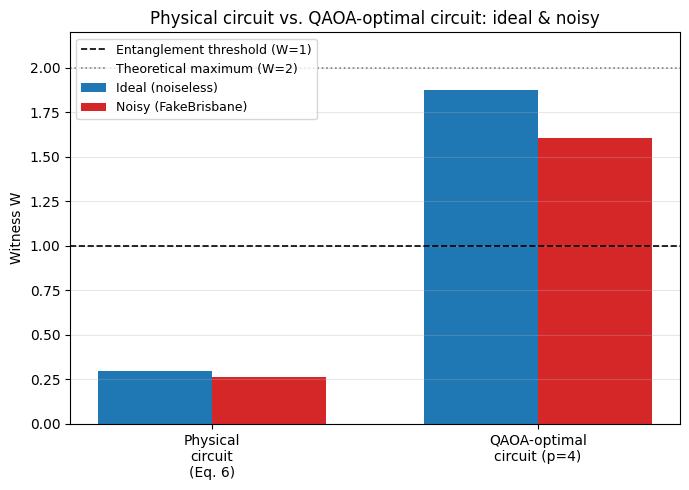

In [15]:
labels = ["Physical\ncircuit\n(Eq. 6)", "QAOA-optimal\ncircuit (p=4)"]
ideal_vals = [abs(S_ideal), abs(S_qaoa_ideal_check)]
noisy_vals = [abs(S_noisy), abs(S_qaoa_noisy)]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(x - width/2, ideal_vals, width, label="Ideal (noiseless)", color="#1f77b4")
ax.bar(x + width/2, noisy_vals, width, label="Noisy (FakeBrisbane)", color="#d62728")
ax.axhline(1.0, color="black", linestyle="--", linewidth=1.2, label="Entanglement threshold (W=1)")
ax.axhline(2.0, color="gray", linestyle=":", linewidth=1.2, label="Theoretical maximum (W=2)")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Witness W")
ax.set_title("Physical circuit vs. QAOA-optimal circuit: ideal & noisy")
ax.set_ylim(0, 2.2)
ax.legend(loc="upper left", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Summary Table & Discussion

| Circuit | Ideal $W$ | Noisy $W$ (FakeBrisbane) | Notes |
|---|---|---|---|
| Physical circuit, Eq. (6), paper's $(\Delta\phi_{LR},\Delta\phi_{RL})=(-0.2,0.7)$ | $\approx0.30$ | lower | Matches the previously documented Eq. (6)-only discrepancy vs. the paper's quoted full-process $W\sim1.16$ (which includes phase from steps 1/3, not modeled here) |
| QAOA, single fixed start, $p=2$ | $\approx1.16$–$1.18$ | — | Coincidentally close to the paper's quoted value; **a local-optimum artifact**, not a physically meaningful match |
| QAOA, multi-start (6 restarts), $p=2$–$4$ | $\approx1.99$ | lower, but comfortably $>1$ | Saturates the theoretical bound |
| Theoretical maximum (any 2-qubit state) | $2.0$ | — | Exact eigenvalue of $\hat X\hat Z+\hat Y\hat Y$ |

**What this notebook did and did not show.** QAOA finding $W\approx2$ does **not** mean the
Bose gravitational-entanglement mechanism itself can reach that value — the *physical*
mechanism is constrained to the specific two-phase diagonal family analyzed in Section 4,
whose own maximum (Section 4's grid scan) tops out well below the abstract $W=2$ bound for
phases in the experimentally realistic $O(1)$ radian regime. What QAOA *does* show is the
purely mathematical ceiling that *any* entanglement-witnessing protocol targeting this
specific witness operator could in principle reach, and how sensitive a naive single-run
variational optimization is to initialization — a caution worth carrying into any future
QAOA/VQE work, gravitational or otherwise.

**Ideas for extending this notebook:**
- **Model steps 1 and 3 explicitly.** Extend the two-qubit reduced picture to the full
  spin-orbital treatment (4 qubits: 2 spin + 2 orbital, or a hybrid discrete/continuous-variable
  treatment) to reproduce the paper's full $W\sim1.16$ claim from first principles, resolving
  the Eq. (6)-only discrepancy rather than just flagging it.
- **Constrained optimization.** Restrict the QAOA-style search to the *physically realizable*
  phase family from Section 4 (rather than the full Hilbert space) and add the paper's
  decoherence/Casimir-Polder constraints as penalty terms — turning this into a genuine
  experimental-design optimization: "what $(m,d,\tau)$ maximizes $W$ subject to feasibility?"
- **Optimize directly against noise**, exactly as suggested in the QAOA-Ising notebook: swap
  `ideal_estimator` for `noisy_estimator` inside the multi-start loop, so the optimizer
  discovers parameters that are robust to `FakeBrisbane`'s specific noise profile rather than
  optimal only in the noiseless limit.
- **Error mitigation.** Since the margin above the $W=1$ threshold is what matters
  operationally, revisit this comparison with `EstimatorV2`'s `resilience_level` options
  once pointed at a real backend, to see how much of the ideal-to-noisy gap can be recovered.


Target system: fake_brisbane (127 qubits)


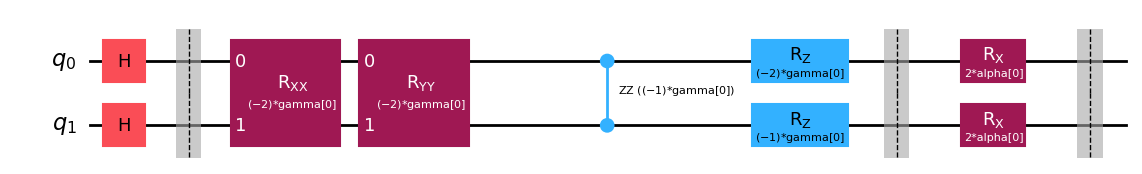

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp

# Primitives & Simulator Engines
from qiskit.primitives import StatevectorEstimator
from qiskit_aer.primitives import EstimatorV2 as AerEstimatorV2
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel

# Fake Backend & Transpiler
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager


# --- 1. Build Bose Cost Hamiltonian ---
def build_cost_bose(n_particles, J_xy, J_z, h_list):
    """
    Builds a Hamiltonian for a 1D Bose interaction chain:
    H_C = - J_xy * sum(X_i X_{i+1} + Y_i Y_{i+1}) - J_z * sum(Z_i Z_{i+1}) - sum(h_i Z_i)
    """
    pauli_list = []
    for i in range(n_particles - 1):
        # XX interaction (Particle tunneling/hopping)
        label_x = ['I'] * n_particles
        label_x[i] = 'X'
        label_x[i + 1] = 'X'
        pauli_list.append((''.join(reversed(label_x)), -float(J_xy)))

        # YY interaction (Particle tunneling/hopping)
        label_y = ['I'] * n_particles
        label_y[i] = 'Y'
        label_y[i + 1] = 'Y'
        pauli_list.append((''.join(reversed(label_y)), -float(J_xy)))

        # ZZ interaction (On-site / Nearest-neighbor interaction)
        label_z = ['I'] * n_particles
        label_z[i] = 'Z'
        label_z[i + 1] = 'Z'
        pauli_list.append((''.join(reversed(label_z)), -float(J_z)))

    # On-site potential terms: -h_i * Z_i
    for i in range(n_particles):
        label = ['I'] * n_particles
        label[i] = 'Z'
        pauli_list.append((''.join(reversed(label)), -float(h_list[i])))

    return SparsePauliOp.from_list(pauli_list)


# --- 2. Build QAOA Parameterized Circuit Template ---
def qaoa_bose_circuit_template(p, cost_h, n_wires):
    """
    Creates a symbolic QAOA ansatz using ParameterVectors for gammas and alphas.
    """
    gammas = ParameterVector('gamma', p)
    alphas = ParameterVector('alpha', p)

    qc = QuantumCircuit(n_wires)
    qc.h(range(n_wires))  # Initial state |+>^N
    qc.barrier()

    for layer in range(p):
        gamma = gammas[layer]
        alpha = alphas[layer]

        # Cost Layer Evolution: exp(-i * gamma * H_C)
        for pauli_string, coeff in cost_h.to_list():
            real_coeff = coeff.real
            reversed_str = list(reversed(pauli_string))
            active_qubits = [i for i, ch in enumerate(reversed_str) if ch != 'I']
            pauli_types = [reversed_str[i] for i in active_qubits]

            if len(active_qubits) == 1 and pauli_types[0] == 'Z':
                qc.rz(2 * gamma * real_coeff, active_qubits[0])
            elif len(active_qubits) == 2:
                q0, q1 = active_qubits
                term = "".join(pauli_types)
                if term == "ZZ":
                    qc.rzz(2 * gamma * real_coeff, q0, q1)
                elif term == "XX":
                    qc.rxx(2 * gamma * real_coeff, q0, q1)
                elif term == "YY":
                    qc.ryy(2 * gamma * real_coeff, q0, q1)

        qc.barrier()

        # Mixer Layer Evolution: exp(-i * alpha * H_M)
        for wire in range(n_wires):
            qc.rx(2 * alpha, wire)

        qc.barrier()

    return qc


# --- 3. Objective Function Factory ---
def make_cost_function(circuit_template, cost_op, estimator, pass_manager, history_list):
    """
    Transpiles ansatz to backend layout once, then evaluates <H_C> 
    at each iteration step.
    """
    if pass_manager is not None:
        transpiled_circuit = pass_manager.run(circuit_template)
        mapped_cost_op = cost_op.apply_layout(transpiled_circuit.layout)
    else:
        transpiled_circuit = circuit_template
        mapped_cost_op = cost_op

    def cost_func(params):
        bound_circuit = transpiled_circuit.assign_parameters(params)
        job = estimator.run([(bound_circuit, mapped_cost_op)])
        result = job.result()[0]
        energy = float(result.data.evs)
        history_list.append(energy)
        return energy

    return cost_func


# --- 4. Main Execution ---

# Experiment setup
n_particles = 2
p = 1  # 1 layer of QAOA
cost_h = build_cost_bose(n_particles, J_xy=1.0, J_z=0.5, h_list=[1.0, 0.5, -1.0])

# Instantiate primitives
ideal_estimator = StatevectorEstimator()

fake_backend = FakeBrisbane()
print(f"Target system: {fake_backend.name} ({fake_backend.num_qubits} qubits)")

noise_model = NoiseModel.from_backend(fake_backend)
backend_sim = AerSimulator(noise_model=noise_model)
noisy_estimator = AerEstimatorV2(
    options={"backend_options": {"noise_model": noise_model}}
)

pm = generate_preset_pass_manager(optimization_level=3, backend=fake_backend)

# Optimization initial state
np.random.seed(42)
initial_params = np.random.uniform(0, 2 * np.pi, 2 * p)

history_ideal = []
history_noisy = []

# Generate circuit template and plot circuit diagram
qaoa_template = qaoa_bose_circuit_template(p, cost_h, n_particles)
qaoa_template.draw("mpl", fold=False)

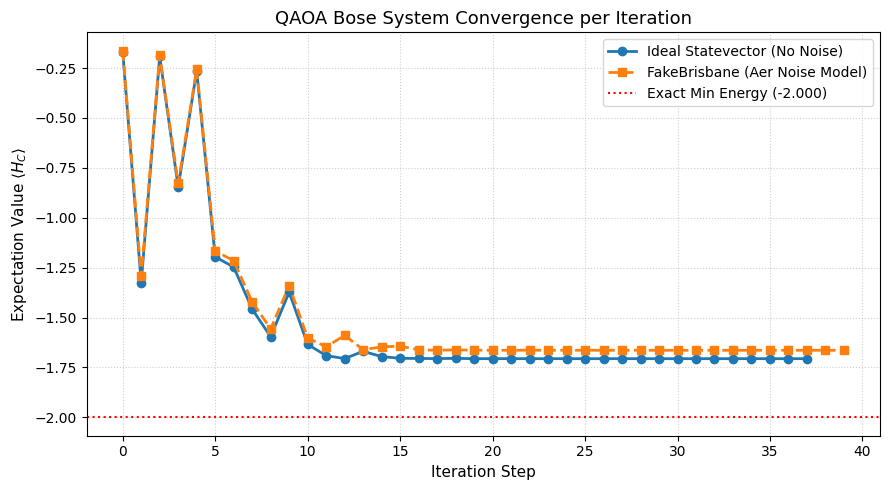

In [17]:
# Run Ideal Optimization
cost_fn_ideal = make_cost_function(qaoa_template, cost_h, ideal_estimator, None, history_ideal)
res_ideal = minimize(cost_fn_ideal, initial_params, method='COBYLA')

# Run Noisy Optimization (FakeBrisbane Aer Simulation)
cost_fn_noisy = make_cost_function(qaoa_template, cost_h, noisy_estimator, pm, history_noisy)
res_noisy = minimize(cost_fn_noisy, initial_params, method='COBYLA')

# Track Exact Ground State for Reference
exact_ground_energy = min(np.linalg.eigvalsh(cost_h.to_matrix()))

# --- 5. Convergence Plotting ---
plt.figure(figsize=(9, 5))
plt.plot(history_ideal, label='Ideal Statevector (No Noise)', marker='o', color='#1f77b4', linewidth=2)
plt.plot(history_noisy, label='FakeBrisbane (Aer Noise Model)', marker='s', color='#ff7f0e', linestyle='--', linewidth=2)
plt.axhline(y=exact_ground_energy, color='r', linestyle=':', label=f'Exact Min Energy ({exact_ground_energy:.3f})')

plt.title("QAOA Bose System Convergence per Iteration", fontsize=13)
plt.xlabel("Iteration Step", fontsize=11)
plt.ylabel("Expectation Value $\\langle H_C \\rangle$", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()